# Sesión 7 · Representación de información y librerías
**Big Data · Práctica de dos horas**

Una red de tiendas andaluzas quiere saber **dónde factura más y dónde compra una mayor proporción de las visitas**. Ambas preguntas usan los mismos registros. Cambian la medida, el denominador y el gráfico que ayuda a decidir.

Al terminar podrás definir qué representa una fila, convertir un registro operativo en una tabla para visualizar, escoger una codificación visual y justificar una herramienta según el público y el uso.

| Minutos | Trabajo |
|---|---|
| 0–20 | Formular la pregunta y elegir las variables visuales |
| 20–45 | Auditar y transformar los registros |
| 45–75 | Construir y leer cinco gráficos |
| 75–95 | Comparar Python, R y herramientas BI |
| 95–120 | Resolver el encargo final y contrastar la interpretación |

**En VS Code.** Abre el cuaderno con las extensiones Python y Jupyter, selecciona un kernel de Python 3 con `pandas`, `numpy`, `matplotlib` e `ipykernel` y pulsa *Ejecutar todo*. Puedes instalar las dependencias desde la terminal del entorno con `python -m pip install pandas numpy matplotlib ipykernel`. Los datos son simulados, se generan dentro del cuaderno y no requieren descargas. Los gráficos y resultados ya están incluidos.

## 1 · De una pregunta a una representación
El destinatario determina la tarea. Quien planifica plantilla quiere detectar días de afluencia alta. Quien compara la eficacia comercial necesita una tasa y el volumen sobre el que se ha calculado. Escribe primero la decisión, la población y el periodo. Después define la **unidad de observación** (aquí, una tienda en un día) y la **medida** que vas a comparar.

Una **marca** es un elemento dibujado, como un punto, una barra o un segmento. Un **canal visual** vincula una variable con una propiedad de esa marca. En una barra horizontal, la posición vertical identifica la tienda y la longitud representa los euros. Una base común facilita comparar magnitudes. Si la barra empieza en un valor distinto de cero, su longitud altera la proporción aparente. En una línea que describe pequeñas variaciones puede tener sentido acotar el eje y señalar sus límites.

| Naturaleza de la variable | Ejemplo | Decisión de representación |
|---|---|---|
| Nominal | Tienda | Distinguir mediante etiquetas o colores cualitativos |
| Ordinal | Satisfacción baja, media, alta | Conservar el orden de las categorías |
| Cuantitativa discreta | Número de compras | Contar, sumar o comparar frecuencias |
| Cuantitativa continua | Duración de la visita | Mostrar forma, dispersión y unidades |
| Temporal | Fecha | Ordenar cronológicamente y declarar la frecuencia |

**Legibilidad.** Usa color secuencial para magnitudes ordenadas y una escala divergente cuando exista un centro significativo, como el cero de una variación. Acompaña el color con texto, símbolos o estilos de línea. Un título plantea la pregunta o comunica el hallazgo. Los ejes, la leyenda y el pie deben permitir reconstruir unidad, periodo, población y origen. Una tabla resulta preferible cuando el lector necesita recuperar cifras exactas.

## 2 · Preparar los datos antes de dibujar
El registro contiene fecha, tienda, visitas al establecimiento, compras e importe facturado en euros. En este caso cada visita admite como máximo una compra. La clave prevista es **fecha + tienda**. Introducimos tres incidencias conocidas para practicar su detección: una variante textual de un nombre, un reenvío idéntico de una fila y un importe ausente. En una fuente real tendríamos que verificar el origen antes de eliminar filas coincidentes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)
filas = []
for dia in pd.date_range("2026-03-02", periods=28):
    for tienda, afluencia, probabilidad, ticket in [
        ("Sevilla", 320, 0.18, 39), ("Córdoba", 175, 0.32, 31),
        ("Huelva", 115, 0.24, 34)
    ]:
        visitas = rng.poisson(afluencia * (1.35 if dia.dayofweek >= 5 else 1))
        compras = rng.binomial(visitas, probabilidad)
        euros = round(compras * rng.uniform(ticket - 3, ticket + 3), 2)
        filas.append([dia.strftime("%d/%m/%Y"), tienda, visitas, compras, euros])

bruto = pd.DataFrame(filas, columns=["fecha", "tienda", "visitas", "compras", "euros"])
bruto.loc[2, "tienda"] = " Huelva "
bruto.loc[9, "euros"] = np.nan
bruto = pd.concat([bruto, bruto.iloc[[0]]], ignore_index=True)
print(bruto.head().to_string(index=False))

     fecha   tienda  visitas  compras   euros
02/03/2026  Sevilla      326       65 2457.06
02/03/2026  Córdoba      192       69 2047.27
02/03/2026  Huelva       107       26  892.35
03/03/2026  Sevilla      304       52 1883.13
03/03/2026  Córdoba      175       61 1778.42


In [2]:
datos = bruto.copy()
datos["tienda"] = datos["tienda"].str.strip()
datos["fecha"] = pd.to_datetime(datos["fecha"], format="%d/%m/%Y")
print("Reenvíos idénticos:", datos.duplicated().sum())
datos = datos.drop_duplicates().sort_values(["tienda", "fecha"]).reset_index(drop=True)
assert not datos.duplicated(["fecha", "tienda"]).any()
assert (datos["compras"].between(0, datos["visitas"])).all()
print("Filas válidas:", len(datos))
print("Días con importe ausente por tienda:")
print(datos.groupby("tienda")["euros"].apply(lambda serie: serie.isna().sum()))

Reenvíos idénticos: 1
Filas válidas: 84
Días con importe ausente por tienda:
tienda
Córdoba    0
Huelva     0
Sevilla    1
Name: euros, dtype: int64


**Cobertura y denominador.** Un importe ausente deja abierta la facturación del día. Para comparar importes usaremos las mismas fechas completas en todas las tiendas. Para medir conversión conservamos todos los días con visitas y compras válidas. La conversión del periodo es $100 \times \sum compras / \sum visitas$. Una media simple de porcentajes diarios concede el mismo peso a un día con diez visitas y a otro con mil. Si el denominador vale cero, la tasa queda indefinida.

In [3]:
completas = datos.groupby("fecha")["euros"].transform("count").eq(datos["tienda"].nunique())
ventas_comparables = datos.loc[completas].copy()
facturacion = ventas_comparables.groupby("tienda")["euros"].sum().sort_values()
resumen = datos.groupby("tienda")[["visitas", "compras"]].sum()
resumen["conversion_pct"] = 100 * resumen["compras"] / resumen["visitas"].replace(0, np.nan)
print("Fechas comparables para ventas:", ventas_comparables["fecha"].nunique())
print(resumen.round(2).to_string())

Fechas comparables para ventas: 27
         visitas  compras  conversion_pct
tienda                                   
Córdoba     5531     1796           32.47
Huelva      3582      891           24.87
Sevilla     9866     1729           17.52


**Formato ancho y largo.** En una tabla ancha cada tienda puede ocupar una columna, algo cómodo para consultar un día concreto. En formato largo, la tienda pasa a ser una variable y cada fila contiene una observación. Una librería puede asignar esa variable al color o a una faceta sin recibir una columna distinta por tienda. Comprueba que la transformación conserva la celda ausente.

In [4]:
ancha = datos.pivot(index="fecha", columns="tienda", values="euros")
larga = ancha.reset_index().melt(id_vars="fecha", var_name="tienda", value_name="euros")
assert len(larga) == len(datos) and larga["euros"].isna().sum() == 1
print(ancha.head(4).to_string())
print(larga.head(4).to_string(index=False))

tienda      Córdoba   Huelva  Sevilla
fecha                                
2026-03-02  2047.27   892.35  2457.06
2026-03-03  1778.42   837.60  1883.13
2026-03-04  2031.05   899.32  2226.35
2026-03-05  1560.18  1130.15      NaN
     fecha  tienda   euros
2026-03-02 Córdoba 2047.27
2026-03-03 Córdoba 1778.42
2026-03-04 Córdoba 2031.05
2026-03-05 Córdoba 1560.18


## 3 · Seleccionar el gráfico según la tarea
| Pregunta | Variables necesarias | Gráfico | Qué revisar |
|---|---|---|---|
| ¿Qué tienda factura más? | Categoría e importe agregado | Barras ordenadas | Base cero y cobertura comparable |
| ¿Cómo evoluciona la demanda? | Fecha y recuento | Línea | Intervalos regulares y huecos |
| ¿Qué valores son frecuentes? | Una medida por observación | Histograma | Anchura de los intervalos y muestra |
| ¿Más visitas coinciden con más compras? | Dos medidas emparejadas | Dispersión | Subgrupos, solapamiento y tamaño muestral |
| ¿Qué fracción de las visitas compra? | Partes excluyentes por tienda | Barras apiladas al 100 % | Denominador y volumen total |

**Escala Big Data.** Para comparar ingresos por tienda, una consulta puede sumar en origen y devolver tres filas. Para un histograma hacen falta recuentos por intervalo. Para una nube con millones de puntos se puede agregar por celdas o tomar una muestra estratificada por tienda. Documenta el muestreo y conserva aparte los casos extremos si son relevantes para la decisión.

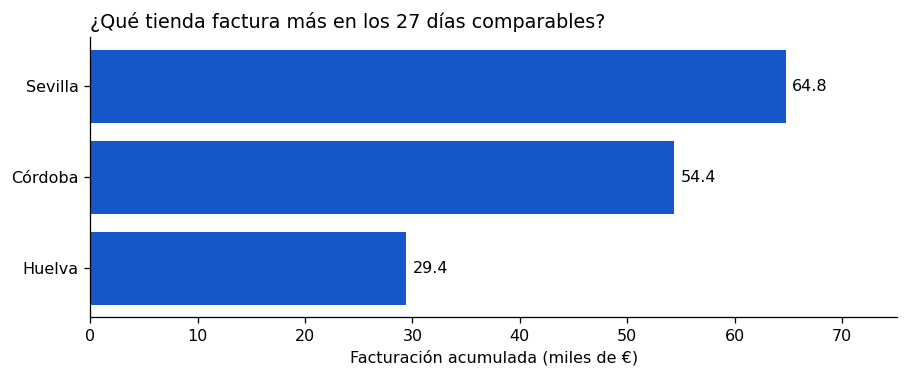

In [5]:
azul, turquesa, gris = "#1458CC", "#92DBDC", "#34455B"
plt.rcParams.update({"figure.figsize": (8, 3.4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlelocation": "left"})
fig, ax = plt.subplots()
barras = ax.barh(facturacion.index, facturacion / 1000, color=azul)
ax.bar_label(barras, fmt="%.1f", padding=4)
ax.margins(x=0.16)
ax.set(title="¿Qué tienda factura más en los 27 días comparables?",
       xlabel="Facturación acumulada (miles de €)")
fig.tight_layout()
plt.show()

**Lectura.** La barra más larga identifica la mayor facturación observada en fechas comunes. Para decidir dónde mejorar el proceso de compra conviene examinar también las visitas y la conversión. La suma en euros combina afluencia, compras y gasto por compra.

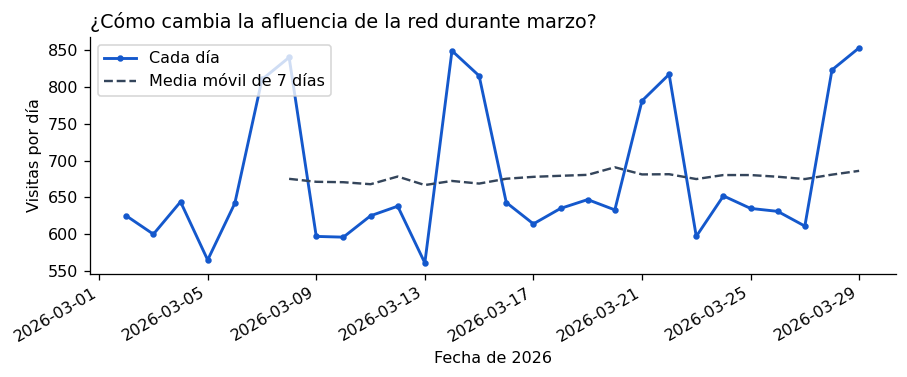

In [6]:
diarias = datos.groupby("fecha")["visitas"].sum()
fig, ax = plt.subplots()
ax.plot(diarias.index, diarias, color=azul, lw=1.8, marker=".", label="Cada día")
ax.plot(diarias.index, diarias.rolling(7).mean(), color=gris, ls="--",
        label="Media móvil de 7 días")
ax.set(title="¿Cómo cambia la afluencia de la red durante marzo?", ylabel="Visitas por día",
       xlabel="Fecha de 2026")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

**Lectura.** La media móvil comienza el séptimo día porque necesita una ventana completa. Atenúa el ciclo semanal y puede ocultar los máximos diarios que interesan para asignar personal. Aquí contamos visitas a establecimientos, por lo que una persona puede aparecer en días o tiendas diferentes.

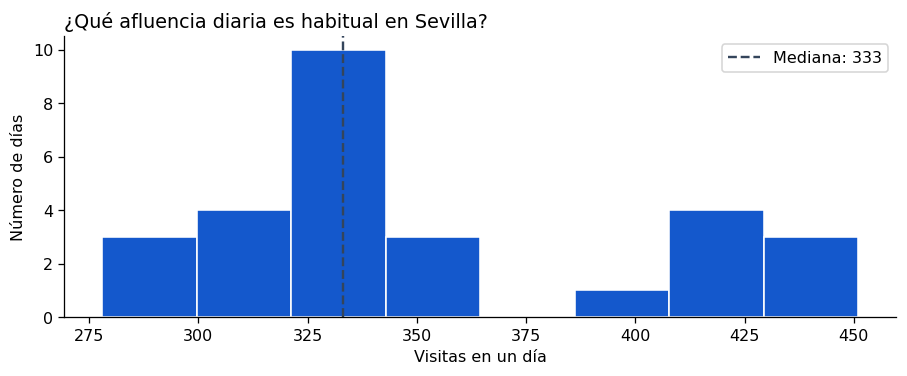

In [7]:
sevilla = datos.loc[datos["tienda"].eq("Sevilla"), "visitas"]
fig, ax = plt.subplots()
ax.hist(sevilla, bins=8, color=azul, edgecolor="white")
ax.axvline(sevilla.median(), color=gris, ls="--", label=f"Mediana: {sevilla.median():.0f}")
ax.set(title="¿Qué afluencia diaria es habitual en Sevilla?",
       xlabel="Visitas en un día", ylabel="Número de días")
ax.legend()
fig.tight_layout()
plt.show()

**Lectura.** Cada barra cuenta días que caen en un intervalo de visitas. Cambia `bins=8` por `bins=4` y comprueba qué detalles desaparecen. Con 28 días la forma del histograma puede cambiar bastante al modificar los límites de los intervalos.

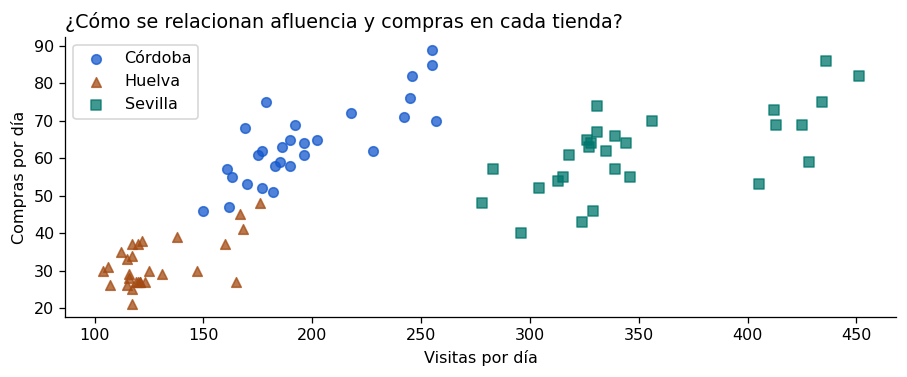

In [8]:
fig, ax = plt.subplots()
for (tienda, grupo), marca, color in zip(datos.groupby("tienda"), ["o", "^", "s"],
                                         [azul, "#A34B12", "#00766C"]):
    ax.scatter(grupo["visitas"], grupo["compras"], marker=marca, color=color,
               alpha=0.75, label=tienda)
ax.set(title="¿Cómo se relacionan afluencia y compras en cada tienda?",
       xlabel="Visitas por día", ylabel="Compras por día")
ax.legend()
fig.tight_layout()
plt.show()

**Lectura.** Cada punto representa una tienda en un día. Compara primero los puntos de la misma tienda. Al mezclar tiendas, las diferencias de afluencia y de conversión pueden cambiar la relación aparente. El diagrama describe asociación y por sí solo no identifica una causa.

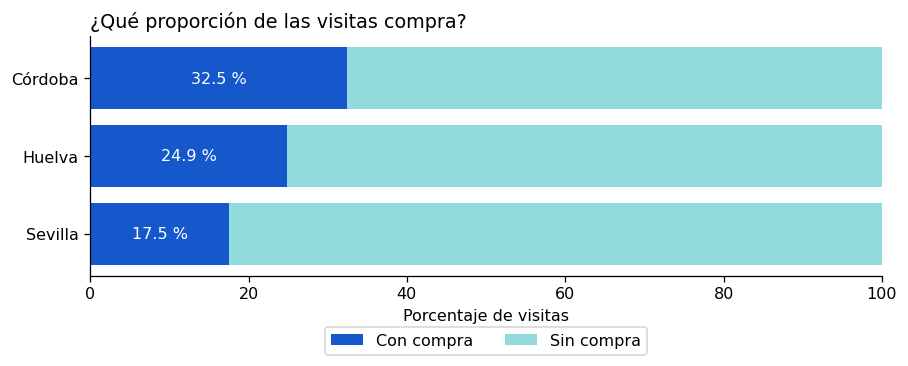

In [9]:
tasas = resumen["conversion_pct"].sort_values()
fig, ax = plt.subplots()
ax.barh(tasas.index, tasas, color=azul, label="Con compra")
ax.barh(tasas.index, 100 - tasas, left=tasas, color=turquesa, label="Sin compra")
for pos, tasa in enumerate(tasas):
    ax.text(tasa / 2, pos, f"{tasa:.1f} %", ha="center", va="center", color="white")
ax.set(xlim=(0, 100), xlabel="Porcentaje de visitas", title="¿Qué proporción de las visitas compra?")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
fig.tight_layout()
plt.show()

**Lectura.** Cada barra representa el 100 % de las visitas a una tienda durante los 28 días. Dos barras de igual longitud pueden representar volúmenes de visitas muy distintos. Consulta los denominadores de la tabla de resumen antes de estimar cuántas compras adicionales supondría mejorar un punto porcentual.

## 4 · Familias de herramientas y criterios de elección
Una librería de trazado controla marcas y ejes. Una librería estadística añade transformaciones y convenciones gráficas. Una gramática declarativa expresa cómo se relacionan datos, canales y capas. Una plataforma de inteligencia de negocio (BI) integra fuentes, medidas, filtros y distribución. Estas familias se solapan.

| Alternativa | Enfoque y ejemplo | Encaje en este caso | Coste o condición que valorar |
|---|---|---|---|
| Python · pandas + Matplotlib | Preparación tabular y control de ejes | Regenerar el informe con pruebas de calidad | El equipo mantiene código y entorno |
| Python · seaborn | Gráficos estadísticos de alto nivel | Explorar distribuciones por tienda con cajas y facetas | Revisar la agregación y los valores predeterminados |
| Python o R · Plotly | Gráficos interactivos con información al pasar el cursor | Consultar fecha y cifras de cada punto | Muchas marcas pueden ralentizar el navegador |
| R · ggplot2 | Capas, estéticas y facetas | Elaborar figuras comparables en un informe de R | Requiere conocer la gramática y mantener el script |
| Power BI | Modelo semántico, medidas y filtros | Reutilizar la conversión en informes por zona | Planificar actualización, permisos y licencias de distribución |
| Tableau | Hojas de exploración visual combinadas en paneles | Explorar tiendas y pasar del resumen al detalle | Organizar fuentes compartidas y permisos de publicación |

**La misma pregunta en tres entornos.** Para reproducir la comparación de facturación de la primera figura, empieza siempre por los mismos 27 días. En Python la serie `facturacion` agrupa y suma. Para probar la alternativa de R o BI, ejecuta en una celda nueva `ventas_comparables.to_csv("ventas_comparables.csv", index=False)`. Para reproducir la conversión exporta la tabla completa `datos` a otro fichero y conserva los 28 días.

**R · Ejemplo equivalente para RStudio o un kernel de R.** El siguiente bloque se muestra como referencia y requiere el paquete ggplot2.

```r
library(ggplot2)
ventas <- read.csv("ventas_comparables.csv")
totales <- aggregate(euros ~ tienda, data = ventas, FUN = sum)
ggplot(totales, aes(x = euros / 1000, y = reorder(tienda, euros))) +
  geom_col(fill = "#1458CC") +
  labs(x = "Facturación (miles de €)", y = NULL,
       title = "Facturación en 27 días comparables") +
  theme_minimal()
```

**BI · Reproducción guiada.** Importa el CSV de fechas comparables, verifica que `euros` sea decimal y sitúa `tienda` en el eje de categorías de un gráfico de barras horizontal. Asigna la suma de `euros` al eje de valores, ordena por facturación y expresa la unidad en euros o miles de euros. Contrasta el total con `facturacion.sum()`. Si dirección quiere filtrar la conversión por fecha, utiliza la tabla completa llamada `Datos`. En Power BI la medida DAX `Conversión = DIVIDE(SUM(Datos[compras]), SUM(Datos[visitas]))` se formatea como porcentaje. Así se recalcula con las filas seleccionadas por el filtro.

**Decisión de herramienta.** Para una figura fija que se regenera junto con la limpieza, Python o R permiten revisar y versionar el procedimiento. Si cada responsable debe filtrar su zona con permisos y una definición compartida de conversión, un informe BI encaja mejor. Elige atendiendo a cómo se actualizará y quién mantendrá el resultado.

## 5 · Actividad final · Preparar el turno de fin de semana
La responsable de operaciones quiere saber **en qué tienda aumentan más las visitas diarias el fin de semana**, tanto en número de visitas adicionales como en porcentaje. Dispone de una diapositiva para la reunión de mañana. Más adelante querrá filtrar el mismo análisis por mes.

1. Define la unidad de observación y prepara una tabla con la media de visitas por tienda y tipo de día. Explica por qué comparar totales de lunes a viernes con totales de sábado y domingo introduciría un sesgo.
2. Calcula el incremento absoluto y el relativo. Diseña un gráfico para una de las dos medidas e incluye la otra en la tabla de apoyo.
3. Redacta dos frases para la responsable. Justifica una herramienta para la reunión y otra opción para el seguimiento mensual. Indica un dato adicional necesario antes de dimensionar turnos.

**Criterios de evaluación (10 puntos).** Comparabilidad de los días y unidad (3), cálculo del incremento y su denominador (3), gráfico legible con unidades (2), interpretación y justificación de la herramienta (2).

In [10]:
# Punto de partida. Añade una celda debajo y desarrolla tu propuesta.
turnos = datos[["fecha", "tienda", "visitas"]].copy()
turnos["tipo_dia"] = np.where(turnos["fecha"].dt.dayofweek >= 5, "Fin de semana", "Laborable")
print(turnos.groupby(["tienda", "tipo_dia"]).size().unstack().to_string())

tipo_dia  Fin de semana  Laborable
tienda                            
Córdoba               8         20
Huelva                8         20
Sevilla               8         20


### Solución orientativa · Consultar después de la puesta en común
En este ejercicio «laborable» designa de lunes a viernes sin ajustar festivos. Se comparan medias por día porque el periodo contiene veinte días de lunes a viernes y ocho de fin de semana por tienda.

tipo_dia  Fin de semana  Laborable  visitas_extra  aumento_pct
tienda                                                        
Córdoba           243.2      179.2           64.0         35.7
Huelva            154.8      117.2           37.6         32.0
Sevilla           425.5      323.1          102.4         31.7


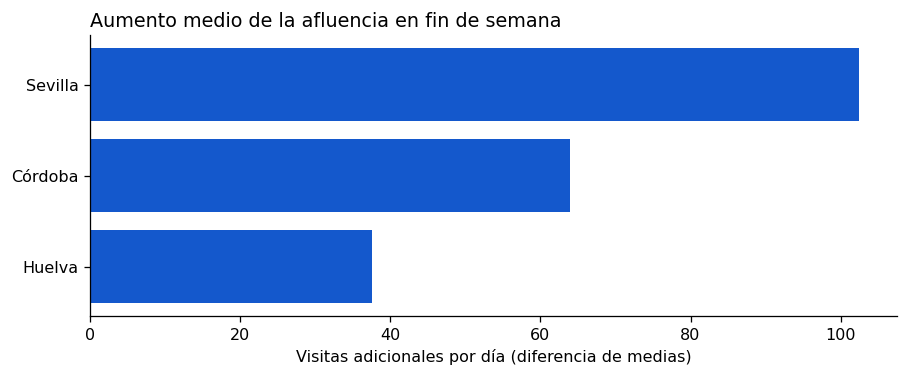

In [11]:
medias = turnos.pivot_table(index="tienda", columns="tipo_dia", values="visitas", aggfunc="mean")
medias["visitas_extra"] = medias["Fin de semana"] - medias["Laborable"]
medias["aumento_pct"] = 100 * medias["visitas_extra"] / medias["Laborable"]
print(medias.round(1).to_string())
orden = medias["visitas_extra"].sort_values()
fig, ax = plt.subplots()
ax.barh(orden.index, orden, color=azul)
ax.set(xlabel="Visitas adicionales por día (diferencia de medias)",
       title="Aumento medio de la afluencia en fin de semana")
fig.tight_layout()
plt.show()

**Interpretación del caso.** Sevilla registra el mayor aumento absoluto, unas 102 visitas adicionales al día. El mayor incremento relativo corresponde a Córdoba (35.7 % sobre su media de lunes a viernes). Para dimensionar turnos se necesita además la distribución horaria y el tiempo medio de atención. Las cuatro semanas simuladas sirven para practicar la comparación. Para evaluar su estabilidad se necesitarían más semanas.

**Entrega.** Para la reunión, una figura estática de Matplotlib con el periodo y la tabla de apoyo cabe en una diapositiva. Para el seguimiento, un panel con selector de mes permite recalcular las medias por tipo de día y mostrar cuántos días sostienen cada cifra.

## Lecturas y documentación
- Claus O. Wilke (2019), *Fundamentals of Data Visualization*. Codificación visual, escalas y elección de figuras. [Edición abierta](https://clauswilke.com/dataviz/)
- Hadley Wickham (2014), *Tidy Data*, Journal of Statistical Software, 59(10). [Artículo](https://doi.org/10.18637/jss.v059.i10)
- Galería de ejemplos por tipo de figura. [Matplotlib](https://matplotlib.org/stable/gallery/index.html)
- Capas y correspondencias entre variables y estéticas. [ggplot2](https://ggplot2.tidyverse.org/)
- Modelos, informes y paneles. [Microsoft Learn](https://learn.microsoft.com/en-us/power-bi/fundamentals/power-bi-overview) · [Tableau Help](https://help.tableau.com/current/pro/desktop/en-us/dashboards.htm)